# Exercise Regression - BERN02
# Name: Ran Tao

In [1]:
import numpy as np
import pandas as pd

In [2]:
data = pd.read_csv("pollution_cleaneddata.csv")

print(data.head())
print(data.columns)

   PREC  JANT  JULT  OVR65  POPN  EDUC  HOUS    DENS  NONW  WWDRK  POOR    HC  \
0  36.0  27.0  71.0    8.1  3.34  11.4  81.5  3243.0   8.8   42.6  11.7  21.0   
1  35.0  23.0  72.0   11.1  3.14  11.0  78.8  4281.0   3.5   50.7  14.4   8.0   
2  44.0  29.0  74.0   10.4  3.21   9.8  81.6  4260.0   0.8   39.4  12.4   6.0   
3  47.0  45.0  79.0    6.5  3.41  11.1  77.5  3125.0  27.1   50.2  20.6  18.0   
4  43.0  35.0  77.0    7.6  3.44   9.6  84.6  6441.0  24.4   43.7  14.3  43.0   

    NOX    SO@  HUMID      MORT  
0  15.0   59.0   59.0   921.870  
1  10.0   39.0   57.0   997.875  
2   6.0   33.0   54.0   962.354  
3   8.0   24.0   56.0   982.291  
4  38.0  206.0   55.0  1071.289  
Index(['PREC', 'JANT', 'JULT', 'OVR65', 'POPN', 'EDUC', 'HOUS', 'DENS', 'NONW',
       'WWDRK', 'POOR', 'HC', 'NOX', 'SO@', 'HUMID', 'MORT'],
      dtype='object')


In [3]:
x = data["POOR"].to_numpy()
y = data["MORT"].to_numpy()

print("Number of observations:", len(x))
print("POOR:", x)
print("MORT:", y)

Number of observations: 60
POOR: [11.7 14.4 12.4 20.6 14.3 25.5 11.3 10.5 12.6 13.2 24.2 10.7 15.1 11.4
 13.9 16.1 12.  12.7 13.6 12.4 18.5 12.3 19.5  9.5 17.9 13.2 13.9 12.
 12.3 17.7 26.4 22.4  9.4  9.8 24.1 12.2 24.2 12.4 13.2 13.8 13.5 15.7
 14.1 17.5 10.8 15.3 14.  12.   9.7 10.1 12.3 11.1 13.6 13.5 10.3 13.2
 10.9 14.  14.5 13. ]
MORT: [ 921.87   997.875  962.354  982.291 1071.289 1030.38   934.7    899.529
 1001.902  912.347 1017.613 1024.885  970.467  985.95   958.839  860.101
  936.234  871.766  959.221  941.181  891.708  871.338  971.122  887.466
  952.529  968.665  919.729  844.053  861.833  989.265 1006.49   861.439
  929.15   857.622  961.009  923.234 1113.156  994.648 1015.023  991.29
  893.991  938.5    946.185 1025.502  874.281  953.56   839.709  911.701
  790.733  899.264  904.155  950.672  972.464  912.202  967.803  823.764
 1003.502  895.696  911.817  954.442]


In [4]:
def local_regression(y, x, n_neighbors, x_pred):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x_pred = np.atleast_1d(x_pred).astype(float)

    predictions = []
    standard_errors = []

    for x0 in x_pred:
        # Find the nearest neighboring points
        distances = np.abs(x - x0)
        indices = np.argsort(distances)[:n_neighbors]

        x_local = x[indices]
        y_local = y[indices]

        # Local linear regression
        X = np.column_stack((np.ones(len(x_local)), x_local))

        beta = np.linalg.lstsq(X, y_local, rcond=None)[0]

        # Prediction
        x0_vector = np.array([1.0, x0])
        y_pred = x0_vector @ beta

        # Residual variance
        residuals = y_local - X @ beta
        n = len(y_local)
        p = X.shape[1]
        sigma2 = np.sum(residuals**2) / (n - p)

        # Standard error of the expected value
        XtX_inv = np.linalg.inv(X.T @ X)
        se = np.sqrt(
            sigma2 * (x0_vector @ XtX_inv @ x0_vector)
        )

        predictions.append(y_pred)
        standard_errors.append(se)

    return np.array(predictions), np.array(standard_errors)

In [5]:
def choose_neighbors(y, x, neighbor_values):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    cv_errors = []

    for k in neighbor_values:
        squared_errors = []

        for i in range(len(x)):
            # Leave one observation out
            x_train = np.delete(x, i)
            y_train = np.delete(y, i)

            prediction, _ = local_regression(
                y_train,
                x_train,
                k,
                [x[i]]
            )

            squared_errors.append((y[i] - prediction[0])**2)

        cv_errors.append(np.mean(squared_errors))

    best_k = neighbor_values[np.argmin(cv_errors)]

    return best_k, cv_errors

In [6]:
neighbor_values = list(range(5, 21))

best_k, cv_errors = choose_neighbors(
    y,
    x,
    neighbor_values
)

for k, error in zip(neighbor_values, cv_errors):
    print(f"k = {k:2d}, CV MSE = {error:.3f}")

print("\nBest number of neighbors:", best_k)

k =  5, CV MSE = 5002.648
k =  6, CV MSE = 4466.819
k =  7, CV MSE = 4381.336
k =  8, CV MSE = 4123.655
k =  9, CV MSE = 4047.560
k = 10, CV MSE = 3923.309
k = 11, CV MSE = 3655.750
k = 12, CV MSE = 3623.367
k = 13, CV MSE = 3625.540
k = 14, CV MSE = 3647.059
k = 15, CV MSE = 3616.016
k = 16, CV MSE = 3629.073
k = 17, CV MSE = 3656.427
k = 18, CV MSE = 3728.749
k = 19, CV MSE = 3685.627
k = 20, CV MSE = 3675.618

Best number of neighbors: 15


In [7]:
x_new = np.array([10, 18, 25])

predictions, standard_errors = local_regression(
    y,
    x,
    best_k,
    x_new
)

results = pd.DataFrame({
    "POOR": x_new,
    "Predicted MORT": predictions,
    "Standard Error": standard_errors
})

results

,POOR,Predicted MORT,Standard Error
0,10,902.909317,18.075584
1,18,959.492269,18.681719
2,25,1009.030913,25.490395


In [9]:
print(f"Number of neighbors used: {best_k}")
print()

for poor, pred, se in zip(x_new, predictions, standard_errors):
    print(
        f"POOR = {poor:2.0f}%: "
        f"Expected MORT = {pred:.2f}, "
        f"SE = {se:.2f}"
    )

Number of neighbors used: 15

POOR = 10%: Expected MORT = 902.91, SE = 18.08
POOR = 18%: Expected MORT = 959.49, SE = 18.68
POOR = 25%: Expected MORT = 1009.03, SE = 25.49


## Results

The number of neighboring points was selected using leave-one-out cross-validation. 
The lowest cross-validation mean squared error was obtained with 15 neighbors.

Using local linear regression with 15 neighboring observations, the predictions are:

| POOR (%) | Expected MORT | Standard Error |
|----------|---------------|----------------|
| 10       | 902.91        | 18.08          |
| 18       | 959.49        | 18.68          |
| 25       | 1009.03       | 25.49          |

The predicted mortality rate increases as POOR increases from 10% to 25%.

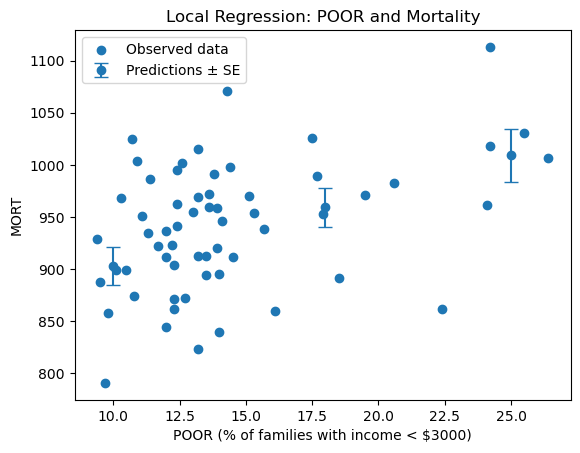

In [10]:
import matplotlib.pyplot as plt

plt.scatter(x, y, label="Observed data")
plt.errorbar(
    x_new,
    predictions,
    yerr=standard_errors,
    fmt="o",
    capsize=5,
    label="Predictions ± SE"
)

plt.xlabel("POOR (% of families with income < $3000)")
plt.ylabel("MORT")
plt.title("Local Regression: POOR and Mortality")
plt.legend()
plt.show()